## 0. Librerias y Funciones

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
pd.options.display.max_rows=100
pd.options.display.max_columns=500
import os
import sys
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pycaret
from pycaret.classification import load_model, predict_model
import mlflow
import mlflow.catboost
from dython.nominal import associations
from catboost import CatBoostClassifier
import psutil
import optuna
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
import joblib

In [2]:
import sbp_modelo as sbp

In [3]:
def assign_weights_v2(valor, a, b):
    c = (a/100) / b
    if valor <= 1500: return 0.25 + a/100 
    elif valor > 1500   and valor <= 3500: return 0.25 - 0.64954160 * (a/100 + c)
    elif valor > 3500 and valor <= 15000: return  0.25 - 0.35045840 * (a/100 + c)
    elif valor > 15000: return 0.25 + c

In [4]:
def calcular_prec_pesos_con_CV(X,y,X_valid,y_valid,features_cat,hiperparams,wt):
    gbm = lgb.LGBMRegressor(**hiperparams)
    gbm.fit(X, y, sample_weight=wt, categorical_feature=features_cat)

    y_pred_train = np.exp(gbm.predict(X_valid))
    y_real_train = np.exp(y_valid)

    df_prec_w = sbp.calcular_coincidencia_v0(y_pred_train, y_real_train, 0.3)

    bins = [999,1500,3500,15000,float("inf")]
    df_prec_w_x_int = sbp.calcular_precision_x_intervalos(y_pred_train, y_real_train,0.3,bins)

    sobre = df_prec_w["Sobreestimacion"].iloc[0]
    coinc = df_prec_w["Coincidencia"].iloc[0]

    coinc_1 = df_prec_w_x_int["Coincidencia"].iloc[0]
    coinc_2 = df_prec_w_x_int["Coincidencia"].iloc[3]

    return coinc,sobre,coinc_1,coinc_2

In [5]:
def cross_val_with_pruning_sw(trial, X, y, model_fn, n_splits, random_state=None, sample_weight=None):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Extraer los pesos correspondientes al conjunto de entrenamiento
        sw_train = sample_weight[train_idx] if sample_weight is not None else None

        model = model_fn(trial)

        model.fit(
            X_train, y_train,
            sample_weight=sw_train,
            eval_set=[(X_val, y_val)],
            eval_metric="mae",
            callbacks=[
                LightGBMPruningCallback(trial, metric="l1"),
                early_stopping(stopping_rounds=50,verbose=False) ]
        )

        preds = model.predict(X_val)
        score = mean_absolute_error(y_val, preds)
        scores.append(score)

    return scores

---

## 1. Lectura de la data

In [6]:
PROCESSED_DATA_DIR = "../data/processed/"
MLRUNS_DIR = "../mlruns/"
LOGS_DIR = "../logs/"
MODELS_DIR = "../models/"
OPTUNA_DIR = "../optuna/"

In [7]:
# Importando tabla
df_train = pd.read_parquet(PROCESSED_DATA_DIR+"train.parquet")
df_test = pd.read_parquet(PROCESSED_DATA_DIR+"test.parquet")

print("Train:", df_train.shape)
print("Test:", df_test.shape)

Train: (4629620, 8)
Test: (1157406, 8)


In [8]:
df_train

,type,amount,entTrxType,oldbalanceOrg,origTrxAmount,oldbalanceDest,destTrxAmount,isFraud
5508643,CASH_OUT,19951.73,CC,49660.00,-19951.73,0.00,19951.73,0
2321526,PAYMENT,6357.25,CM,56503.00,-6357.25,0.00,NaN,0
4111006,CASH_IN,107883.86,CC,3488609.81,107883.86,885589.22,-107883.86,0
2716783,PAYMENT,6514.55,CM,31372.00,-6514.55,0.00,NaN,0
2137572,PAYMENT,2422.66,CM,0.00,0.00,0.00,NaN,0
...,...,...,...,...,...,...,...,...
4219997,PAYMENT,5842.27,CM,0.00,0.00,0.00,NaN,0
2133781,PAYMENT,5588.34,CM,271979.00,-5588.34,0.00,NaN,0
2747322,PAYMENT,563.96,CM,35041.00,-563.96,0.00,NaN,0
3707395,PAYMENT,1510.22,CM,396999.67,-1510.21,0.00,NaN,0


In [9]:
target = 'isFraud'
cols_cat = ['type','entTrxType']
cols_num = ['amount','oldbalanceOrg','origTrxAmount','oldbalanceDest','destTrxAmount']
cols_total = cols_cat + cols_num

---

## 2. RFE (Eliminación Recursiva de Variables)

### 2.1. Correlacion

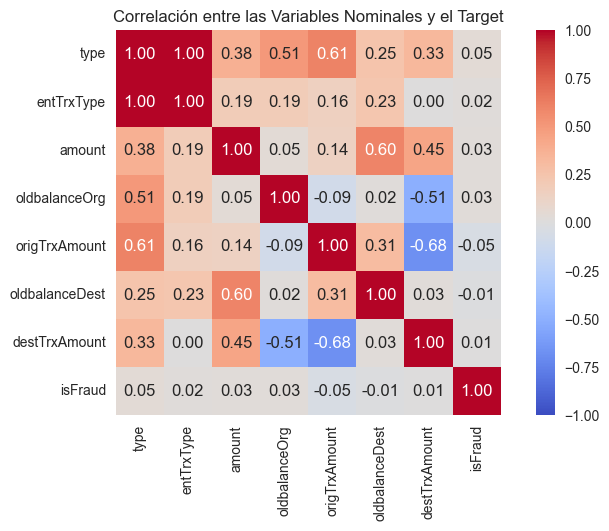

In [8]:
assoc = associations(df_train[cols_total+[target]],
    nominal_columns=cols_cat,
    numerical_columns=cols_num+[target],
    plot=True,num_num_assoc='spearman',nom_num_assoc='correlation_ratio',nom_nom_assoc='cramer',
    nan_strategy='drop_sample_pairs',
    cmap='coolwarm',title='Correlación entre las Variables Nominales y el Target',figsize=(9,5))

In [9]:
# type correlaciona mejor con isFraud que entTrxType
# Se considerara el resto de variables a pesar de que correlacionen hasta 68%

In [ ]:
cols_total.remove('entTrxType')
cols_cat.remove('entTrxType')

### 2.2. RFE

In [12]:
X = df_train[cols_total]
y = df_train[target]
X.shape

(4629620, 6)

In [13]:
for col in cols_cat:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

In [14]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=666)

In [14]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(random_state=666, verbose=0, allow_writing_files=False)
list_num_var = list(range(1, X_train.shape[1] + 1))

with sbp.MedirTiempoEjecucion():
    df_rfe = sbp.eliminacion_recursiva_de_variables(
        X_train, y_train, model, list_num_var, umbral=0.5, X_val=X_val, y_val=y_val,
        experiment_name="rfe_catboost", run_name="RFE catboost", tracking_uri=MLRUNS_DIR)

2026/10/07 21:06:18 INFO mlflow.tracking.fluent: Experiment with name 'rfe_catboost' does not exist. Creating a new experiment.


  0%|          | 0/5 [00:00<?, ?it/s]

2026/10/07 21:24:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 21:43:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 22:05:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 22:31:37 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 23:01:49 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Número de variables seleccionadas: 1

Variables seleccionadas: ['amount']


,Num_Variables,Var_Eliminada,Train_AUC,Train_PR_AUC,Train_Accuracy,Train_F1,Train_Precision,Train_Recall,Train_Gini,Train_KS,Val_AUC,Val_PR_AUC,Val_Accuracy,Val_F1,Val_Precision,Val_Recall,Val_Gini,Val_KS
0,1,oldbalanceOrg,0.818476,0.010148,0.999227,0.000000,0.000000,0.000000,0.636952,0.457607,0.785313,0.009245,0.999227,0.000000,0.000000,0.000000,0.570627,0.419321
1,2,origTrxAmount,0.999230,0.683713,0.999505,0.569686,0.867143,0.424179,0.998461,0.988209,0.996322,0.629971,0.999478,0.554839,0.815718,0.420391,0.992644,0.980095
2,3,destTrxAmount,0.999368,0.746095,0.999531,0.618022,0.832938,0.491265,0.998737,0.988982,0.996509,0.686931,0.999474,0.577624,0.762014,0.465084,0.993017,0.982583
3,4,oldbalanceDest,0.999792,0.921311,0.999764,0.826243,0.958487,0.726066,0.999584,0.992494,0.996807,0.854289,0.999714,0.791174,0.907776,0.701117,0.993613,0.984139
4,5,type,0.999963,0.971554,0.999844,0.890114,0.976230,0.817959,0.999926,0.997172,0.997584,0.835623,0.999706,0.790769,0.880137,0.717877,0.995167,0.984141


Tiempo transcurrido: 1 horas, 55 minutos y 31.080 segundos


In [ ]:
# El modelo con 5 variables obtiene Val_F1_Score de 0.790769
# El modelo con 4 variables obtiene Val_F1_Score de 0.791174 pero con menos val_recall
# >>> Nos quedamos con las 5 variables.

---

## 3. Optimizacion

In [14]:
print("Features:", cols_total)

Features: ['type', 'amount', 'oldbalanceOrg', 'origTrxAmount', 'oldbalanceDest', 'destTrxAmount']


In [15]:
print(f"Hilos Lógicos: ",psutil.cpu_count(logical=True))
print(f"Núcleos físicos: ",psutil.cpu_count(logical=False))

Hilos Lógicos:  16
Núcleos físicos:  12


### Estudio 1

In [83]:
seed_vf = 666

def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, thread_count=8,
        verbose=0, allow_writing_files=False,
        # Variables
        iterations       = trial.suggest_int('iterations', 500, 1500),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        depth            = trial.suggest_int('depth', 4, 10),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 1, 50, log=True),
        random_strength  = trial.suggest_float('random_strength', 0.1, 10, log=True),
        rsm              = trial.suggest_float('rsm', 0.5, 1.0),
        border_count     = trial.suggest_categorical('border_count', [64, 128, 254]),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
    )
    # Bootstrap
    bootstrap = trial.suggest_categorical('bootstrap_type', ['Bernoulli', 'Bayesian'])
    params['bootstrap_type'] = bootstrap
    if bootstrap == 'Bernoulli':
        params['subsample'] = trial.suggest_float('subsample', 0.5, 1.0)
    else:
        params['bagging_temperature'] = trial.suggest_float('bagging_temperature', 0.0, 10.0)

    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 4)
        params['one_hot_max_size']   = trial.suggest_categorical('one_hot_max_size', [2, 10, 25])
    
    return params


def cv_catboost_con_pruning(trial, X, y, params, n_splits=5, umbral=0.5, random_state=seed_vf):
    y = np.asarray(y)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores, met_folds = [], []

    for fold, (i_tr, i_va) in enumerate(skf.split(X, y)):
        model = CatBoostClassifier(**params)
        model.fit(X.iloc[i_tr], y[i_tr])

        met = sbp.metricas_clasificacion_binaria(y[i_va], model.predict_proba(X.iloc[i_va])[:, 1], umbral)
        met_folds.append(met)
        scores.append(met["PR_AUC"]) # metrica

        if mlflow.active_run():
            mlflow.log_metrics({f"fold_{k}": v for k, v in met.items() if np.isfinite(v)}, step=fold)

        media_parcial = float(np.nanmean(scores))
        if np.isfinite(media_parcial):
            trial.report(media_parcial, step=fold)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return scores, met_folds


def optimizar_catboost_optuna(X, y, experiment_name,
                              study_name="CATB_fraude_prauc", n_trials=50,
                              cat_features=None, X_val=None, y_val=None,
                              n_splits=5, umbral=0.5, run_name="Optuna CatBoost",
                              db_name="estudio_catboost_fraude.db"):

    # MLflow
    mlflow.set_tracking_uri(MLRUNS_DIR)
    mlflow.set_experiment(experiment_name)

    ratio = float((np.asarray(y) == 0).sum() / (np.asarray(y) == 1).sum())

    def objetivo(trial):
        params = construir_params(trial, ratio, cat_features)
        podado = False
        with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True):
            mlflow.log_params(trial.params)
            try:
                scores, met_folds = cv_catboost_con_pruning(trial, X, y, params, n_splits, umbral)
            except optuna.TrialPruned:
                mlflow.set_tag("estado", "PRUNED")
                podado = True
            else:
                mlflow.set_tag("estado", "COMPLETE")
                resumen = {}
                for k in met_folds[0].keys():
                    vals = [m[k] for m in met_folds]
                    resumen[f"cv_{k}_mean"] = float(np.nanmean(vals))
                    resumen[f"cv_{k}_std"] = float(np.nanstd(vals))
                mlflow.log_metrics({k: v for k, v in resumen.items() if np.isfinite(v)})
                trial.set_user_attr("scores_cross_val", scores)
                trial.set_user_attr("metricas_cv", resumen)
        if podado:
            raise optuna.TrialPruned()
        return float(np.nanmean(scores))

    estudio = optuna.create_study(
        direction="maximize",
        study_name=study_name,
        storage=f"sqlite:///{OPTUNA_DIR+db_name}",
        load_if_exists=True,
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=1, interval_steps=1),
        sampler=optuna.samplers.TPESampler(seed=seed_vf),
    )

    with mlflow.start_run(run_name=run_name):  # run padre
        mlflow.log_params({"n_trials": n_trials, "n_splits": n_splits, "seed": seed_vf,
                           "metrica_optimizada": "PR-AUC", "umbral": umbral,
                           "ratio_desbalance": round(ratio, 1), "study_name": study_name})

        estudio.optimize(objetivo, n_trials=n_trials, n_jobs=1)

        # Mejor trial
        best = estudio.best_trial
        mlflow.log_metric("best_pr_auc_cv", best.value)
        mlflow.log_dict(best.params, "mejores_hiperparametros.json")
        mlflow.log_text(estudio.trials_dataframe().to_csv(index=False), "trials.csv")

        # Reentrenar el mejor modelo con todos los datos
        best_params = construir_params(optuna.trial.FixedTrial(best.params), ratio, cat_features)
        modelo_final = CatBoostClassifier(**best_params).fit(X, y)

        # Metricas de CV del trial ganador
        mlflow.log_metrics({f"best_{k}": v for k, v in best.user_attrs.get("metricas_cv", {}).items()
                            if np.isfinite(v)})

        # Metricas del modelo final: train y validacion
        met_train = sbp.metricas_clasificacion_binaria(y, modelo_final.predict_proba(X)[:, 1], umbral)
        mlflow.log_metrics({f"train_{k}": v for k, v in met_train.items() if np.isfinite(v)})

        if X_val is not None:
            met_val = sbp.metricas_clasificacion_binaria(y_val, modelo_final.predict_proba(X_val)[:, 1], umbral)
            mlflow.log_metrics({f"val_{k}": v for k, v in met_val.items() if np.isfinite(v)})

        mlflow.catboost.log_model(modelo_final, artifact_path="model")

    print(f"\nMejor trial {best.number}: PR-AUC CV = {best.value:.4f}")
    print(best.params)
    
    return estudio, modelo_final

In [19]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude",
    n_trials=50, cat_features=None, X_val=X_val, y_val=y_val, umbral=0.5, db_name="estudio_catboost_fraude.db")

[I 2026-10-08 00:00:07,752] A new study created in RDB with name: CATB_fraude_prauc
[I 2026-10-08 00:36:07,032] Trial 0 finished with value: 0.8080250446984086 and parameters: {'iterations': 1201, 'learning_rate': 0.12540421798589482, 'depth': 8, 'l2_leaf_reg': 17.242848273004956, 'random_strength': 7.996794115960455, 'rsm': 0.5063515985173839, 'border_count': 64, 'scale_pos_weight': 38.099067555096205, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 1.9289200304058374}. Best is trial 0 with value: 0.8080250446984086.
[I 2026-10-08 01:19:46,866] Trial 1 finished with value: 0.8406262049742239 and parameters: {'iterations': 1201, 'learning_rate': 0.0240712454492742, 'depth': 9, 'l2_leaf_reg': 1.0201869499588057, 'random_strength': 0.16815713804621452, 'rsm': 0.5554768359937233, 'border_count': 254, 'scale_pos_weight': 11.43043920858065, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 9.783469850151286}. Best is trial 1 with value: 0.8406262049742239.
[I 2026-10-08 01:52:00,819


Mejor trial 40: PR-AUC CV = 0.8690
{'iterations': 1195, 'learning_rate': 0.04862830951101363, 'depth': 7, 'l2_leaf_reg': 1.451940770223384, 'random_strength': 0.10049358234425926, 'rsm': 0.7275251958270231, 'border_count': 254, 'scale_pos_weight': 17.71668095991105, 'bootstrap_type': 'Bernoulli', 'subsample': 0.5713279770612507}


In [21]:
# ver en dashboard: uv run optuna-dashboard sqlite:///estudio_catboost_fraude.db

### Estudio 2: parametros ajustados

In [33]:
def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, thread_count=8,
        verbose=0, allow_writing_files=False,
        # Nuevos Fijos
        bootstrap_type   = 'Bernoulli',
        border_count     = 254,
        # Rangos ajustados
        iterations       = trial.suggest_int('iterations', 900, 1300),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.1),
        depth            = trial.suggest_int('depth', 6, 9),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 1, 3),
        random_strength  = trial.suggest_float('random_strength', 0.1, 0.5),
        rsm              = trial.suggest_float('rsm', 0.55, 1.0),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
    )
    
    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 4)
        params['one_hot_max_size']   = trial.suggest_categorical('one_hot_max_size', [2, 10, 25])
    
    return params

In [34]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude2",
    n_trials=50, cat_features=cols_cat, X_val=X_val, y_val=y_val, umbral=0.5, db_name="estudio_catboost_fraude2.db")

2026/10/09 08:53:27 INFO mlflow.tracking.fluent: Experiment with name 'optuna_catboost_fraude2' does not exist. Creating a new experiment.
[I 2026-10-09 08:53:27,556] A new study created in RDB with name: CATB_fraude_prauc
[I 2026-10-09 09:24:51,126] Trial 0 finished with value: 0.8663732690726272 and parameters: {'iterations': 1180, 'learning_rate': 0.08597679785653911, 'depth': 8, 'l2_leaf_reg': 2.4557161144961497, 'random_strength': 0.48058318297853575, 'rsm': 0.5557164386656455, 'scale_pos_weight': 19.361182613710476, 'subsample': 0.5244063969, 'max_ctr_complexity': 1, 'one_hot_max_size': 25}. Best is trial 0 with value: 0.8663732690726272.
[I 2026-10-09 10:22:11,099] Trial 1 finished with value: 0.8632624342993049 and parameters: {'iterations': 977, 'learning_rate': 0.07307602769493832, 'depth': 7, 'l2_leaf_reg': 2.5489589085371773, 'random_strength': 0.10204353550551995, 'rsm': 0.6007859441342687, 'scale_pos_weight': 2.2143525757460334, 'subsample': 0.6238341143475151, 'max_ctr_c


Mejor trial 25: PR-AUC CV = 0.8695
{'iterations': 1286, 'learning_rate': 0.08545541288875462, 'depth': 6, 'l2_leaf_reg': 1.3829397461485382, 'random_strength': 0.3876734041228281, 'rsm': 0.6688462819585717, 'scale_pos_weight': 14.340571391365522, 'subsample': 0.5269083174453981, 'max_ctr_complexity': 4, 'one_hot_max_size': 25}


In [35]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude2",
    n_trials=25, cat_features=cols_cat, X_val=X_val, y_val=y_val, umbral=0.5, db_name="estudio_catboost_fraude2.db")

[I 2026-10-10 11:51:10,241] Using an existing study with `study_name='CATB_fraude_prauc'` instead of creating a new one.
[I 2026-10-10 12:22:50,700] Trial 50 finished with value: 0.86650590123859 and parameters: {'iterations': 1277, 'learning_rate': 0.09270524535589135, 'depth': 6, 'l2_leaf_reg': 1.1176288841390651, 'random_strength': 0.486003919677341, 'rsm': 0.6904487079207423, 'scale_pos_weight': 17.643319514956545, 'subsample': 0.5749848044668185, 'max_ctr_complexity': 4, 'one_hot_max_size': 25}. Best is trial 25 with value: 0.8694553975875522.
[I 2026-10-10 12:53:29,498] Trial 51 finished with value: 0.8672393071283256 and parameters: {'iterations': 1282, 'learning_rate': 0.09739032697167264, 'depth': 6, 'l2_leaf_reg': 1.3114386675571859, 'random_strength': 0.4821379708045672, 'rsm': 0.7694090901906864, 'scale_pos_weight': 14.903356342702182, 'subsample': 0.5142781586274009, 'max_ctr_complexity': 4, 'one_hot_max_size': 25}. Best is trial 25 with value: 0.8694553975875522.
[I 2026-


Mejor trial 53: PR-AUC CV = 0.8695
{'iterations': 1225, 'learning_rate': 0.09760190087559223, 'depth': 6, 'l2_leaf_reg': 1.152086362166391, 'random_strength': 0.4936985760495367, 'rsm': 0.6823929711554764, 'scale_pos_weight': 27.073499986019737, 'subsample': 0.544214514231399, 'max_ctr_complexity': 4, 'one_hot_max_size': 25}


In [39]:
df_optuna = estudio.trials_dataframe()
df_optuna.to_csv(OPTUNA_DIR+'optuna_results.csv', index=False)

In [76]:
df_optuna = pd.read_csv(OPTUNA_DIR+'optuna_results.csv')
df_optuna['params'] = df_optuna['system_attrs_tpe:relative_params:0'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df_optuna.head()

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_max_ctr_complexity,params_one_hot_max_size,params_random_strength,params_rsm,params_scale_pos_weight,params_subsample,user_attrs_metricas_cv,user_attrs_scores_cross_val,system_attrs_tpe:relative_params:0,state,params
0,0,0.866373,2026-10-09 08:53:27.608373,2026-10-09 09:24:51.087360,0 days 00:31:23.478987,8,1180,2.455716,0.085977,1,25,0.480583,0.555716,19.361183,0.524406,"{'cv_AUC_mean': 0.9983867651142668, 'cv_AUC_st...","[0.8772033660966272, 0.8772322756058337, 0.859...",NaN,COMPLETE,NaN
1,1,0.863262,2026-10-09 09:24:51.137931,2026-10-09 10:22:11.092741,0 days 00:57:19.954810,7,977,2.548959,0.073076,1,2,0.102044,0.600786,2.214353,0.623834,"{'cv_AUC_mean': 0.9986128236834289, 'cv_AUC_st...","[0.8729776408393823, 0.8753247977559676, 0.854...",NaN,COMPLETE,NaN
2,2,0.864903,2026-10-09 10:22:11.108803,2026-10-09 11:02:06.464997,0 days 00:39:55.356194,8,1264,1.518264,0.098051,4,25,0.333525,0.696561,583.345363,0.813202,"{'cv_AUC_mean': 0.9981344017849679, 'cv_AUC_st...","[0.8719515065947447, 0.8764127466142091, 0.857...",NaN,COMPLETE,NaN
3,3,0.850366,2026-10-09 11:02:06.480255,2026-10-09 11:40:52.987625,0 days 00:38:46.507370,9,1048,1.438818,0.016765,1,25,0.131737,0.769051,3.007297,0.914233,"{'cv_AUC_mean': 0.9982162362838711, 'cv_AUC_st...","[0.8545109191450039, 0.8591570753593007, 0.850...",NaN,COMPLETE,NaN
4,4,0.863850,2026-10-09 11:40:53.003747,2026-10-09 12:17:52.355006,0 days 00:36:59.351259,7,1241,1.032441,0.047627,4,10,0.219685,0.709200,602.906099,0.893068,"{'cv_AUC_mean': 0.9984365300972439, 'cv_AUC_st...","[0.8721899649667854, 0.8762640463361754, 0.856...",NaN,COMPLETE,NaN


#### Mejor modelo: PR-AUC

In [45]:
best_hiperparams = estudio.best_trial.params
best_hiperparams['bootstrap_type'] = 'Bernoulli'
best_hiperparams['border_count'] = 254
best_hiperparams['cat_features'] = ['type']
best_hiperparams['border_count'] = 254
best_hiperparams['loss_function'] = 'Logloss'
best_hiperparams['random_seed'] = seed_vf
best_hiperparams['thread_count'] = 8
best_hiperparams['verbose'] = 0
best_hiperparams['allow_writing_files'] = False
best_hiperparams

{'iterations': 1225,
 'learning_rate': 0.09760190087559223,
 'depth': 6,
 'l2_leaf_reg': 1.152086362166391,
 'random_strength': 0.4936985760495367,
 'rsm': 0.6823929711554764,
 'scale_pos_weight': 27.073499986019737,
 'subsample': 0.544214514231399,
 'max_ctr_complexity': 4,
 'one_hot_max_size': 25,
 'bootstrap_type': 'Bernoulli',
 'border_count': 254,
 'cat_features': ['type'],
 'loss_function': 'Logloss',
 'random_seed': 666,
 'thread_count': 8,
 'verbose': 0,
 'allow_writing_files': False}

In [17]:
model = CatBoostClassifier(**best_hiperparams)
model.fit(X_train, y_train)
joblib.dump(model, MODELS_DIR+'prauc_best_model.pkl')

['../models/best_model.pkl']

#### Mejor modelo: Segun relacion F1 y PR-AUC

In [77]:
import ast
metricas = ['cv_F1_mean','cv_PR_AUC_mean','cv_Recall_mean','cv_Precision_mean']
for met in metricas:
    df_optuna[met] = df_optuna['user_attrs_metricas_cv'].apply(
        lambda x: ast.literal_eval(x).get(met) if isinstance(x, str) else x)

In [78]:
df_optuna.sort_values(by='cv_PR_AUC_mean',ascending=False).head()

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_max_ctr_complexity,params_one_hot_max_size,params_random_strength,params_rsm,params_scale_pos_weight,params_subsample,user_attrs_metricas_cv,user_attrs_scores_cross_val,system_attrs_tpe:relative_params:0,state,params,cv_F1_mean,cv_PR_AUC_mean,cv_Recall_mean,cv_Precision_mean
53,53,0.869548,2026-10-10 13:24:26.721525,2026-10-10 13:54:28.993500,0 days 00:30:02.271975,6,1225,1.152086,0.097602,4,25,0.493699,0.682393,27.073500,0.544215,"{'cv_AUC_mean': 0.9984667756303406, 'cv_AUC_st...","[0.8782829562918185, 0.8815159622181702, 0.860...","{""depth"": 6, ""iterations"": 1225, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1225, 'l2_leaf_reg'...",0.627917,0.869548,0.885041,0.486643
25,25,0.869455,2026-10-09 22:43:29.520506,2026-10-09 23:15:04.974646,0 days 00:31:35.454140,6,1286,1.382940,0.085455,4,25,0.387673,0.668846,14.340571,0.526908,"{'cv_AUC_mean': 0.9985622952723732, 'cv_AUC_st...","[0.8782664447701485, 0.8781545280047356, 0.861...","{""depth"": 6, ""iterations"": 1286, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1286, 'l2_leaf_reg'...",0.677322,0.869455,0.846608,0.564583
65,65,0.869144,2026-10-10 18:54:47.596242,2026-10-10 19:23:06.791113,0 days 00:28:19.194871,6,1295,1.078683,0.095695,4,25,0.439850,0.646835,15.299838,0.580222,"{'cv_AUC_mean': 0.9984661929580666, 'cv_AUC_st...","[0.8808946916510336, 0.8797088126292588, 0.861...","{""depth"": 6, ""iterations"": 1295, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1295, 'l2_leaf_reg'...",0.672858,0.869144,0.845555,0.558758
37,37,0.868958,2026-10-10 05:05:11.151819,2026-10-10 05:36:43.165862,0 days 00:31:32.014043,6,1281,1.515923,0.094149,4,25,0.292746,0.706161,14.198842,0.557002,"{'cv_AUC_mean': 0.9984076969274882, 'cv_AUC_st...","[0.880182679588233, 0.8800062063500229, 0.8600...","{""depth"": 6, ""iterations"": 1281, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1281, 'l2_leaf_reg'...",0.682058,0.868958,0.846605,0.571167
54,54,0.868918,2026-10-10 13:54:29.015987,2026-10-10 14:25:15.678745,0 days 00:30:46.662758,6,1287,1.309301,0.083937,4,25,0.447561,0.753729,14.568844,0.502639,"{'cv_AUC_mean': 0.9985310752631895, 'cv_AUC_st...","[0.8772249276717284, 0.8808466795592288, 0.861...","{""depth"": 6, ""iterations"": 1287, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1287, 'l2_leaf_reg'...",0.671305,0.868918,0.848006,0.555660


In [79]:
df_optuna.sort_values(by='cv_F1_mean',ascending=False).head()

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_max_ctr_complexity,params_one_hot_max_size,params_random_strength,params_rsm,params_scale_pos_weight,params_subsample,user_attrs_metricas_cv,user_attrs_scores_cross_val,system_attrs_tpe:relative_params:0,state,params,cv_F1_mean,cv_PR_AUC_mean,cv_Recall_mean,cv_Precision_mean
5,5,0.857990,2026-10-09 12:17:52.369383,2026-10-09 12:45:19.765616,0 days 00:27:27.396233,8,972,2.343763,0.089562,3,10,0.202625,0.743861,1.125116,0.617497,"{'cv_AUC_mean': 0.998543854962189, 'cv_AUC_std...","[0.8658711045318641, 0.8704160787553897, 0.850...",NaN,COMPLETE,NaN,0.816764,0.857990,0.722912,0.939114
3,3,0.850366,2026-10-09 11:02:06.480255,2026-10-09 11:40:52.987625,0 days 00:38:46.507370,9,1048,1.438818,0.016765,1,25,0.131737,0.769051,3.007297,0.914233,"{'cv_AUC_mean': 0.9982162362838711, 'cv_AUC_st...","[0.8545109191450039, 0.8591570753593007, 0.850...",NaN,COMPLETE,NaN,0.814577,0.850366,0.727106,0.926414
1,1,0.863262,2026-10-09 09:24:51.137931,2026-10-09 10:22:11.092741,0 days 00:57:19.954810,7,977,2.548959,0.073076,1,2,0.102044,0.600786,2.214353,0.623834,"{'cv_AUC_mean': 0.9986128236834289, 'cv_AUC_st...","[0.8729776408393823, 0.8753247977559676, 0.854...",NaN,COMPLETE,NaN,0.812730,0.863262,0.733394,0.911845
12,12,0.847805,2026-10-09 16:08:13.757385,2026-10-09 16:42:40.761347,0 days 00:34:27.003962,7,1182,1.921169,0.017165,4,25,0.441611,0.912637,3.213852,0.941672,"{'cv_AUC_mean': 0.9983095738099431, 'cv_AUC_st...","[0.8515345024070387, 0.8549230874875497, 0.846...","{""depth"": 7, ""iterations"": 1182, ""l2_leaf_reg""...",COMPLETE,"{'depth': 7, 'iterations': 1182, 'l2_leaf_reg'...",0.811547,0.847805,0.728504,0.916274
14,14,0.863965,2026-10-09 17:14:33.510676,2026-10-09 17:46:58.205227,0 days 00:32:24.694551,6,1107,1.962295,0.096056,2,25,0.485021,0.743177,3.533607,0.970534,"{'cv_AUC_mean': 0.998607247079893, 'cv_AUC_std...","[0.876367247303004, 0.8721417877083152, 0.8552...","{""depth"": 6, ""iterations"": 1107, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1107, 'l2_leaf_reg'...",0.793181,0.863965,0.756456,0.834126


In [80]:
df_optuna['Hprom']=2/(1/df_optuna['cv_F1_mean']+1/df_optuna['cv_PR_AUC_mean'])
df_optuna.sort_values(by='Hprom',ascending=False).head()

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_max_ctr_complexity,params_one_hot_max_size,params_random_strength,params_rsm,params_scale_pos_weight,params_subsample,user_attrs_metricas_cv,user_attrs_scores_cross_val,system_attrs_tpe:relative_params:0,state,params,cv_F1_mean,cv_PR_AUC_mean,cv_Recall_mean,cv_Precision_mean,Hprom
1,1,0.863262,2026-10-09 09:24:51.137931,2026-10-09 10:22:11.092741,0 days 00:57:19.954810,7,977,2.548959,0.073076,1,2,0.102044,0.600786,2.214353,0.623834,"{'cv_AUC_mean': 0.9986128236834289, 'cv_AUC_st...","[0.8729776408393823, 0.8753247977559676, 0.854...",NaN,COMPLETE,NaN,0.812730,0.863262,0.733394,0.911845,0.837235
5,5,0.857990,2026-10-09 12:17:52.369383,2026-10-09 12:45:19.765616,0 days 00:27:27.396233,8,972,2.343763,0.089562,3,10,0.202625,0.743861,1.125116,0.617497,"{'cv_AUC_mean': 0.998543854962189, 'cv_AUC_std...","[0.8658711045318641, 0.8704160787553897, 0.850...",NaN,COMPLETE,NaN,0.816764,0.857990,0.722912,0.939114,0.836870
3,3,0.850366,2026-10-09 11:02:06.480255,2026-10-09 11:40:52.987625,0 days 00:38:46.507370,9,1048,1.438818,0.016765,1,25,0.131737,0.769051,3.007297,0.914233,"{'cv_AUC_mean': 0.9982162362838711, 'cv_AUC_st...","[0.8545109191450039, 0.8591570753593007, 0.850...",NaN,COMPLETE,NaN,0.814577,0.850366,0.727106,0.926414,0.832087
12,12,0.847805,2026-10-09 16:08:13.757385,2026-10-09 16:42:40.761347,0 days 00:34:27.003962,7,1182,1.921169,0.017165,4,25,0.441611,0.912637,3.213852,0.941672,"{'cv_AUC_mean': 0.9983095738099431, 'cv_AUC_st...","[0.8515345024070387, 0.8549230874875497, 0.846...","{""depth"": 7, ""iterations"": 1182, ""l2_leaf_reg""...",COMPLETE,"{'depth': 7, 'iterations': 1182, 'l2_leaf_reg'...",0.811547,0.847805,0.728504,0.916274,0.829280
14,14,0.863965,2026-10-09 17:14:33.510676,2026-10-09 17:46:58.205227,0 days 00:32:24.694551,6,1107,1.962295,0.096056,2,25,0.485021,0.743177,3.533607,0.970534,"{'cv_AUC_mean': 0.998607247079893, 'cv_AUC_std...","[0.876367247303004, 0.8721417877083152, 0.8552...","{""depth"": 6, ""iterations"": 1107, ""l2_leaf_reg""...",COMPLETE,"{'depth': 6, 'iterations': 1107, 'l2_leaf_reg'...",0.793181,0.863965,0.756456,0.834126,0.827061


In [84]:
best_hiperparams = df_optuna.iloc[12]['params']
best_hiperparams['bootstrap_type'] = 'Bernoulli'
best_hiperparams['border_count'] = 254
best_hiperparams['cat_features'] = ['type']
best_hiperparams['border_count'] = 254
best_hiperparams['loss_function'] = 'Logloss'
best_hiperparams['random_seed'] = seed_vf
best_hiperparams['thread_count'] = 8
best_hiperparams['verbose'] = 0
best_hiperparams['allow_writing_files'] = False
best_hiperparams

{'depth': 7,
 'iterations': 1182,
 'l2_leaf_reg': 1.9211694335936724,
 'learning_rate': 0.017164739575668837,
 'max_ctr_complexity': 4,
 'one_hot_max_size': 25,
 'random_strength': 0.4416109207055639,
 'rsm': 0.9126372208609816,
 'scale_pos_weight': 3.213852015050451,
 'subsample': 0.9416724122586554,
 'bootstrap_type': 'Bernoulli',
 'border_count': 254,
 'cat_features': ['type'],
 'loss_function': 'Logloss',
 'random_seed': 666,
 'thread_count': 8,
 'verbose': 0,
 'allow_writing_files': False}

In [85]:
model = CatBoostClassifier(**best_hiperparams)
model.fit(X_train, y_train)
joblib.dump(model, MODELS_DIR+'f1prauc_best_model.pkl')

['../models/f1prauc_best_model.pkl']

### Estudio 3: Cambiando funcion objetivo a f1-score

In [15]:
seed_vf = 666

def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, #thread_count=8,
        verbose=0, allow_writing_files=False,
        # Variables
        iterations       = trial.suggest_int('iterations', 500, 1500),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        depth            = trial.suggest_int('depth', 4, 10),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 1, 50, log=True),
        random_strength  = trial.suggest_float('random_strength', 0.1, 10, log=True),
        rsm              = trial.suggest_float('rsm', 0.5, 1.0),
        border_count     = trial.suggest_categorical('border_count', [64, 128, 254]),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
    )
    # Bootstrap
    bootstrap = trial.suggest_categorical('bootstrap_type', ['Bernoulli', 'Bayesian'])
    params['bootstrap_type'] = bootstrap
    if bootstrap == 'Bernoulli':
        params['subsample'] = trial.suggest_float('subsample', 0.5, 1.0)
    else:
        params['bagging_temperature'] = trial.suggest_float('bagging_temperature', 0.0, 10.0)

    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 4)
        params['one_hot_max_size']   = trial.suggest_categorical('one_hot_max_size', [2, 10, 25])
    
    return params


def mejor_umbral_f1(y_real, y_proba, umbral_defecto=0.5):
    try:
        prec, rec, thr = precision_recall_curve(y_real, y_proba)
        f1s = 2 * prec * rec / (prec + rec + 1e-12)
        return float(thr[np.nanargmax(f1s[:-1])])
    except Exception:
        return umbral_defecto


def cv_catboost_con_pruning(trial, X, y, params, n_splits=5, umbral=0.5,
                            buscar_umbral=False, random_state=seed_vf):
    y = np.asarray(y)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores, met_folds = [], []

    for fold, (i_tr, i_va) in enumerate(skf.split(X, y)):
        model = CatBoostClassifier(**params)
        model.fit(X.iloc[i_tr], y[i_tr])

        proba = model.predict_proba(X.iloc[i_va])[:, 1]
        umbral_fold = mejor_umbral_f1(y[i_va], proba, umbral) if buscar_umbral else umbral

        met = sbp.metricas_clasificacion_binaria(y[i_va], proba, umbral_fold)
        met["Umbral"] = umbral_fold
        met_folds.append(met)
        scores.append(met["F1"])   # metrica que guia a Optuna

        if mlflow.active_run():
            mlflow.log_metrics({f"fold_{k}": v for k, v in met.items() if np.isfinite(v)}, step=fold)

        media_parcial = float(np.nanmean(scores))
        if np.isfinite(media_parcial):

            trial.report(media_parcial, step=fold)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return scores, met_folds


def optimizar_catboost_optuna(X, y, experiment_name,
                              study_name="CATB_fraude_f1", n_trials=50,
                              cat_features=None, X_val=None, y_val=None,
                              n_splits=5, umbral=0.5, buscar_umbral=False,
                              run_name="Optuna CatBoost F1",
                              db_name="estudio_catboost_fraude3.db"):

    # MLflow
    mlflow.set_tracking_uri(MLRUNS_DIR)
    mlflow.set_experiment(experiment_name)

    ratio = float((np.asarray(y) == 0).sum() / (np.asarray(y) == 1).sum())

    def objetivo(trial):
        params = construir_params(trial, ratio, cat_features)
        podado = False
        with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True):
            mlflow.log_params(trial.params)
            try:
                scores, met_folds = cv_catboost_con_pruning(trial, X, y, params, n_splits,
                                                            umbral, buscar_umbral)
            except optuna.TrialPruned:
                mlflow.set_tag("estado", "PRUNED")
                podado = True
            else:

                mlflow.set_tag("estado", "COMPLETE")
                resumen = {}
                for k in met_folds[0].keys():
                    vals = [m[k] for m in met_folds]
                    resumen[f"cv_{k}_mean"] = float(np.nanmean(vals))
                    resumen[f"cv_{k}_std"] = float(np.nanstd(vals))
                mlflow.log_metrics({k: v for k, v in resumen.items() if np.isfinite(v)})
                trial.set_user_attr("scores_cross_val", scores)
                trial.set_user_attr("metricas_cv", resumen)
        if podado:
            raise optuna.TrialPruned()
        return float(np.nanmean(scores))

    estudio = optuna.create_study(
        direction="maximize",
        study_name=study_name,
        storage=f"sqlite:///{OPTUNA_DIR+db_name}",
        load_if_exists=True,
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=1, interval_steps=1),
        sampler=optuna.samplers.TPESampler(seed=seed_vf),
    )

    with mlflow.start_run(run_name=run_name):  # run padre
        mlflow.log_params({"n_trials": n_trials, "n_splits": n_splits, "seed": seed_vf,
                           "metrica_optimizada": "F1", "buscar_umbral": buscar_umbral,
                           "umbral": umbral, "ratio_desbalance": round(ratio, 1),
                           "study_name": study_name})

        estudio.optimize(objetivo, n_trials=n_trials, n_jobs=1)

        # Mejor trial
        best = estudio.best_trial

        mlflow.log_metric("best_f1_cv", best.value)
        mlflow.log_dict(best.params, "mejores_hiperparametros.json")
        mlflow.log_text(estudio.trials_dataframe().to_csv(index=False), "trials.csv")

        # Umbral final: promedio de los umbrales por fold si se busco, o el fijo
        metricas_cv = best.user_attrs.get("metricas_cv", {})
        umbral_final = float(metricas_cv.get("cv_Umbral_mean", umbral)) if buscar_umbral else umbral
        mlflow.log_param("umbral_final", round(umbral_final, 6))
        estudio.set_user_attr("umbral_final", umbral_final)

        # Reentrenar el mejor modelo con todos los datos
        best_params = construir_params(optuna.trial.FixedTrial(best.params), ratio, cat_features)
        modelo_final = CatBoostClassifier(**best_params).fit(X, y)

        # Metricas de CV del trial ganador
        mlflow.log_metrics({f"best_{k}": v for k, v in metricas_cv.items() if np.isfinite(v)})

        # Metricas del modelo final: train y validacion (al umbral final)
        met_train = sbp.metricas_clasificacion_binaria(y, modelo_final.predict_proba(X)[:, 1], umbral_final)
        mlflow.log_metrics({f"train_{k}": v for k, v in met_train.items() if np.isfinite(v)})

        if X_val is not None:
            met_val = sbp.metricas_clasificacion_binaria(y_val, modelo_final.predict_proba(X_val)[:, 1], umbral_final)
            mlflow.log_metrics({f"val_{k}": v for k, v in met_val.items() if np.isfinite(v)})

        mlflow.catboost.log_model(modelo_final, artifact_path="model")

    print(f"\nMejor trial {best.number}: F1 CV = {best.value:.4f}  |  umbral final = {umbral_final:.4f}")
    print(best.params)

    return estudio, modelo_final

In [91]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude_f1",
    n_trials=50, cat_features=cols_cat, X_val=X_val, y_val=y_val, buscar_umbral=True)

2026/10/12 16:45:08 INFO mlflow.tracking.fluent: Experiment with name 'optuna_catboost_fraude_f1' does not exist. Creating a new experiment.
[I 2026-10-12 16:45:09,863] A new study created in RDB with name: CATB_fraude_f1
[I 2026-10-12 17:21:31,978] Trial 0 finished with value: 0.42827190608755483 and parameters: {'iterations': 1201, 'learning_rate': 0.12540421798589482, 'depth': 8, 'l2_leaf_reg': 17.242848273004956, 'random_strength': 7.996794115960455, 'rsm': 0.5063515985173839, 'border_count': 64, 'scale_pos_weight': 38.099067555096205, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 1.9289200304058374, 'max_ctr_complexity': 3, 'one_hot_max_size': 10}. Best is trial 0 with value: 0.42827190608755483.
[I 2026-10-12 17:37:06,079] Trial 1 finished with value: 0.5046031335303898 and parameters: {'iterations': 612, 'learning_rate': 0.013942930268767357, 'depth': 5, 'l2_leaf_reg': 1.0951605102000956, 'random_strength': 2.8486710922859353, 'rsm': 0.6700174709773135, 'border_count': 25

KeyboardInterrupt: 

In [ ]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude_f1",
    n_trials=50, cat_features=cols_cat, X_val=X_val, y_val=y_val, buscar_umbral=True)

[I 2026-10-13 00:58:03,011] Using an existing study with `study_name='CATB_fraude_f1'` instead of creating a new one.
[I 2026-10-13 02:00:01,026] Trial 12 finished with value: 0.802780469132555 and parameters: {'iterations': 1027, 'learning_rate': 0.025204639276487268, 'depth': 5, 'l2_leaf_reg': 41.86963538798302, 'random_strength': 8.70907125868132, 'rsm': 0.7542859792141194, 'border_count': 128, 'scale_pos_weight': 2.9325730240954075, 'bootstrap_type': 'Bernoulli', 'subsample': 0.5372985962946963, 'max_ctr_complexity': 2, 'one_hot_max_size': 2}. Best is trial 12 with value: 0.802780469132555.
[I 2026-10-13 02:41:18,690] Trial 13 finished with value: 0.6800157637101435 and parameters: {'iterations': 684, 'learning_rate': 0.021114832681308864, 'depth': 5, 'l2_leaf_reg': 22.002332490932684, 'random_strength': 3.388013922020212, 'rsm': 0.8602645982983844, 'border_count': 128, 'scale_pos_weight': 21.701637907416377, 'bootstrap_type': 'Bernoulli', 'subsample': 0.5236364919870482, 'max_ctr_

### Estudio 4: Ajustando hiperparametros con funcion objetivo a f1-score

In [16]:
def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, thread_count=-1,
        verbose=0, allow_writing_files=False,
        # Nuevos Fijos
        bootstrap_type = 'Bernoulli',
        border_count = 128,
        # Variables
        iterations       = trial.suggest_int('iterations', 800, 1200),
        learning_rate    = trial.suggest_float('learning_rate', 0.05, 0.2, log=True),
        depth            = trial.suggest_int('depth', 4, 6),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 10, 50, log=True),
        random_strength  = trial.suggest_float('random_strength', 1, 10, log=True),
        rsm              = trial.suggest_float('rsm', 0.8, 1.0),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
    )
    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 3)
        params['one_hot_max_size']   = 2
    
    return params

In [17]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude_f1_2", study_name="CATB_fraude_f1_2",
    n_trials=50, cat_features=cols_cat, X_val=X_val, y_val=y_val, buscar_umbral=True)

[I 2026-10-14 16:49:17,454] Using an existing study with `study_name='CATB_fraude_f1_2'` instead of creating a new one.
[I 2026-10-14 17:54:39,005] Trial 11 finished with value: 0.58680228018378 and parameters: {'iterations': 1080, 'learning_rate': 0.16114654818511273, 'depth': 6, 'l2_leaf_reg': 32.26643239813631, 'random_strength': 8.942479586759175, 'rsm': 0.8025406394069535, 'scale_pos_weight': 19.361182613710476, 'subsample': 0.5244063969, 'max_ctr_complexity': 1}. Best is trial 9 with value: 0.8115629799122187.
[I 2026-10-14 18:38:33,717] Trial 12 finished with value: 0.2905738870063124 and parameters: {'iterations': 1003, 'learning_rate': 0.06599803969772243, 'depth': 6, 'l2_leaf_reg': 13.640356598967765, 'random_strength': 5.021630485318783, 'rsm': 0.8586456211738468, 'scale_pos_weight': 256.97654490211676, 'subsample': 0.5025544193818999, 'max_ctr_complexity': 1}. Best is trial 9 with value: 0.8115629799122187.
[I 2026-10-14 19:08:15,848] Trial 13 finished with value: 0.1849838


Mejor trial 57: F1 CV = 0.8129  |  umbral final = 0.5000
{'iterations': 801, 'learning_rate': 0.11718268257797362, 'depth': 6, 'l2_leaf_reg': 18.34208340462806, 'random_strength': 1.703621297230939, 'rsm': 0.9773399545826901, 'scale_pos_weight': 1.034690791863266, 'subsample': 0.5871512752396807, 'max_ctr_complexity': 2}


In [19]:
df_optuna = estudio.trials_dataframe()
df_optuna.to_csv(OPTUNA_DIR+'optuna_results_f1.csv', index=False)

In [25]:
import ast
df_optuna = pd.read_csv(OPTUNA_DIR+'optuna_results_f1.csv')
df_optuna['params'] = df_optuna['system_attrs_tpe:relative_params:0'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

In [21]:
import ast
metricas = ['cv_F1_mean','cv_PR_AUC_mean','cv_Recall_mean','cv_Precision_mean']
for met in metricas:
    df_optuna[met] = df_optuna['user_attrs_metricas_cv'].apply(
        lambda x: ast.literal_eval(x).get(met) if isinstance(x, str) else x)

In [23]:
df_optuna.sort_values(by='cv_F1_mean',ascending=False).head()

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_max_ctr_complexity,params_random_strength,params_rsm,params_scale_pos_weight,params_subsample,user_attrs_metricas_cv,user_attrs_scores_cross_val,system_attrs_tpe:relative_params:0,state,params,cv_F1_mean,cv_PR_AUC_mean,cv_Recall_mean,cv_Precision_mean
57,57,0.812917,2026-10-15 15:05:08.946907,2026-10-15 15:34:48.414479,0 days 00:29:39.467572,6,801,18.342083,0.117183,2,1.703621,0.977340,1.034691,0.587151,"{'cv_AUC_mean': 0.9984168134294935, 'cv_AUC_st...","[0.8112449799196787, 0.8162436548223351, 0.818...","{""depth"": 6, ""iterations"": 801, ""l2_leaf_reg"":...",COMPLETE,"{'depth': 6, 'iterations': 801, 'l2_leaf_reg':...",0.812917,0.831964,0.701602,0.966446
59,59,0.812022,2026-10-15 16:05:59.373952,2026-10-15 16:36:00.738568,0 days 00:30:01.364616,6,811,15.370177,0.108122,2,1.360132,0.947656,1.142358,0.631619,"{'cv_AUC_mean': 0.998390573214213, 'cv_AUC_std...","[0.814, 0.8154158215010142, 0.8121827411167513...","{""depth"": 6, ""iterations"": 811, ""l2_leaf_reg"":...",COMPLETE,"{'depth': 6, 'iterations': 811, 'l2_leaf_reg':...",0.812022,0.833402,0.700552,0.965998
26,26,0.811829,2026-10-15 04:40:28.603536,2026-10-15 05:06:37.744863,0 days 00:26:09.141327,6,945,28.323651,0.093284,1,1.636008,0.892853,1.507399,0.672605,"{'cv_AUC_mean': 0.998466169461253, 'cv_AUC_std...","[0.8111332007952287, 0.816, 0.8133198789101918...","{""depth"": 6, ""iterations"": 945, ""l2_leaf_reg"":...",COMPLETE,"{'depth': 6, 'iterations': 945, 'l2_leaf_reg':...",0.811829,0.834591,0.707192,0.953108
31,31,0.811809,2026-10-15 06:11:22.586900,2026-10-15 06:43:12.290860,0 days 00:31:49.703960,6,903,25.750795,0.100193,2,1.685902,0.925595,1.036712,0.615365,"{'cv_AUC_mean': 0.9983935890721842, 'cv_AUC_st...","[0.8133198789101918, 0.8142131979695432, 0.813...","{""depth"": 6, ""iterations"": 903, ""l2_leaf_reg"":...",COMPLETE,"{'depth': 6, 'iterations': 903, 'l2_leaf_reg':...",0.811809,0.832060,0.698806,0.968609
33,33,0.811763,2026-10-15 06:52:20.122418,2026-10-15 07:24:26.556833,0 days 00:32:06.434415,6,880,16.774321,0.103879,2,1.462268,0.956451,1.108924,0.541514,"{'cv_AUC_mean': 0.9983417042771476, 'cv_AUC_st...","[0.8120603015075377, 0.8141414141414142, 0.812...","{""depth"": 6, ""iterations"": 880, ""l2_leaf_reg"":...",COMPLETE,"{'depth': 6, 'iterations': 880, 'l2_leaf_reg':...",0.811763,0.832902,0.701602,0.963159


In [26]:
# se ve que se puede mejorar la métrica pero por tiempo se detendrá la optimizacion

In [ ]:
        iterations       = trial.suggest_int('iterations', 800, 1200),
        learning_rate    = trial.suggest_float('learning_rate', 0.05, 0.2, log=True),
        depth            = trial.suggest_int('depth', 4, 6),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 10, 50, log=True),
        random_strength  = trial.suggest_float('random_strength', 1, 10, log=True),
        rsm              = trial.suggest_float('rsm', 0.8, 1.0),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
    )
    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 3)
        params['one_hot_max_size']   = 2
    

In [27]:
best_hiperparams = df_optuna.iloc[57]['params']
best_hiperparams['bootstrap_type'] = 'Bernoulli'
best_hiperparams['border_count'] = 128
best_hiperparams['cat_features'] = ['type']
best_hiperparams['loss_function'] = 'Logloss'
best_hiperparams['random_seed'] = 666
best_hiperparams['thread_count'] = -1
best_hiperparams['verbose'] = 0
best_hiperparams['allow_writing_files'] = False
best_hiperparams['one_hot_max_size'] = 2
print(best_hiperparams)

{'depth': 6, 'iterations': 801, 'l2_leaf_reg': 18.34208340462806, 'learning_rate': 0.11718268257797362, 'max_ctr_complexity': 2, 'random_strength': 1.703621297230939, 'rsm': 0.9773399545826901, 'scale_pos_weight': 1.034690791863266, 'subsample': 0.5871512752396807, 'bootstrap_type': 'Bernoulli', 'border_count': 128, 'cat_features': ['type'], 'loss_function': 'Logloss', 'random_seed': 666, 'thread_count': -1, 'verbose': 0, 'allow_writing_files': False, 'one_hot_max_size': 2}


In [28]:
model = CatBoostClassifier(**best_hiperparams)
model.fit(X_train, y_train)
joblib.dump(model, MODELS_DIR+'f1_best_model.pkl')

['../models/f1_best_model.pkl']